<a href="https://colab.research.google.com/github/KishoreKumar477/IQube2/blob/main/IQube_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "dataset.csv"

# Load the latest version using dataset_load
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "maharshipandya/-spotify-tracks-dataset",
  file_path
)

print("First 5 records:")
print(df.head(1))
print(df.info())



Using Colab cache for faster access to the '-spotify-tracks-dataset' dataset.
First 5 records:
   Unnamed: 0                track_id      artists album_name track_name  \
0           0  5SuOikwiRyPMVoIQDJUgSV  Gen Hoshino     Comedy     Comedy   

   popularity  duration_ms  explicit  danceability  energy  ...  loudness  \
0          73       230666     False         0.676   0.461  ...    -6.746   

   mode  speechiness  acousticness  instrumentalness  liveness  valence  \
0     0        0.143        0.0322          0.000001     0.358    0.715   

    tempo  time_signature  track_genre  
0  87.917               4     acoustic  

[1 rows x 21 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null

In [ ]:
df.describe()


,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


### 1. Exploratory Data Analysis (EDA) & Preprocessing
We will drop unnecessary columns (like IDs and indices), handle missing values, and scale the numeric features for clustering.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Drop rows with missing values (if any)
df_clean = df.dropna().copy()

# Drop non-numeric identifier columns
cols_to_drop = ['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'track_genre']
features = df_clean.drop(columns=cols_to_drop)

# Scale the features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

print("Scaled features shape:", scaled_features.shape)

Scaled features shape: (113999, 15)


### 2. Finding the Optimal Number of Clusters for K-Means
We will use the Elbow Method to find the optimal number of clusters on a representative sample of our dataset (for speed).

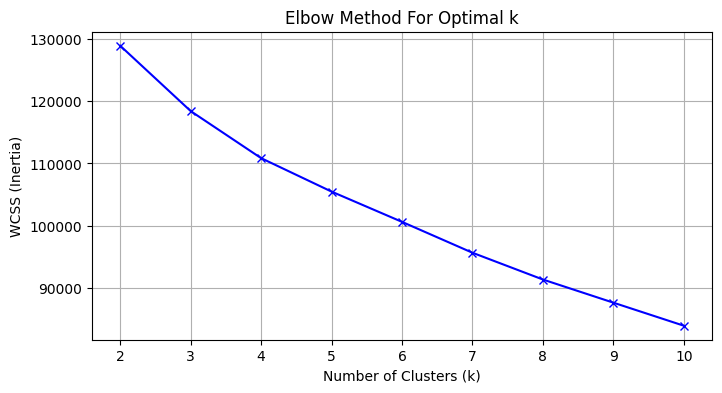

In [ ]:
# Take a sample for fast evaluation
np.random.seed(42)
sample_indices = np.random.choice(scaled_features.shape[0], size=10000, replace=False)
sample_data = scaled_features[sample_indices]

wcss = []
k_range = range(2, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(sample_data)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.title('Elbow Method For Optimal k')
plt.grid(True)
plt.show()

### 3. Apply K-Means and DBSCAN, Evaluate, and Visualize using PCA
We will use PCA to reduce the dimensions to 2D for plotting, and evaluate the clusters using Silhouette Scores.

K-Means Silhouette Score (k=4): 0.1059
DBSCAN Silhouette Score: 0.1879


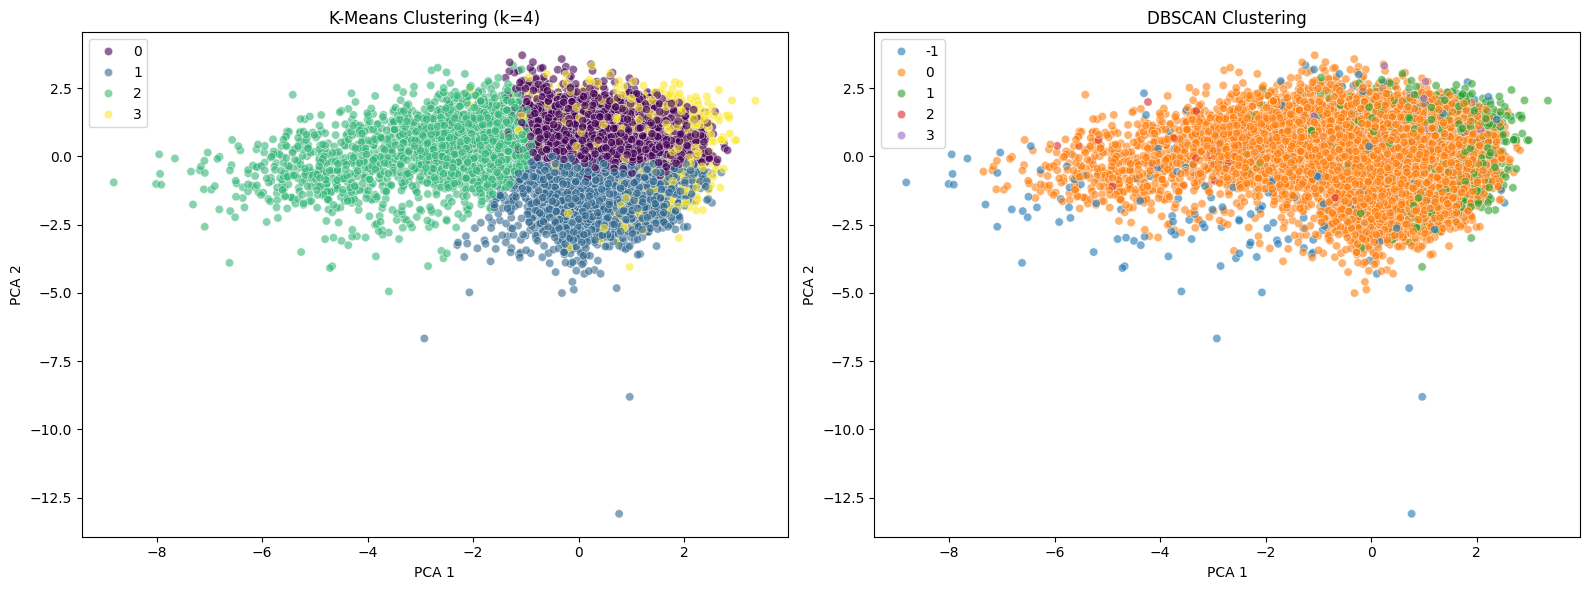

In [ ]:
# Based on the elbow plot, let's select an optimal k (e.g., k=4)
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(sample_data)

# DBSCAN Clustering
dbscan = DBSCAN(eps=3.0, min_samples=10)
dbscan_labels = dbscan.fit_predict(sample_data)

# Silhouette Scores
kmeans_sil = silhouette_score(sample_data, kmeans_labels)
# Exclude noise (-1) from DBSCAN silhouette calculation if present
if len(set(dbscan_labels)) > 1:
    dbscan_sil = silhouette_score(sample_data, dbscan_labels)
else:
    dbscan_sil = "N/A (Only 1 cluster/noise found)"

print(f"K-Means Silhouette Score (k={optimal_k}): {kmeans_sil:.4f}")
print(f"DBSCAN Silhouette Score: {dbscan_sil if isinstance(dbscan_sil, str) else f'{dbscan_sil:.4f}'}")

# Dimensionality reduction for visualization
pca = PCA(n_components=2)
pca_data = pca.fit_transform(sample_data)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# K-Means Visual
sns.scatterplot(x=pca_data[:, 0], y=pca_data[:, 1], hue=kmeans_labels, palette='viridis', ax=ax1, alpha=0.6)
ax1.set_title(f'K-Means Clustering (k={optimal_k})')
ax1.set_xlabel('PCA 1')
ax1.set_ylabel('PCA 2')

# DBSCAN Visual
sns.scatterplot(x=pca_data[:, 0], y=pca_data[:, 1], hue=dbscan_labels, palette='tab10', ax=ax2, alpha=0.6)
ax2.set_title('DBSCAN Clustering')
ax2.set_xlabel('PCA 1')
ax2.set_ylabel('PCA 2')

plt.tight_layout()
plt.show()

### 4. Comparing K-Means Clusters with Track Genres
Since we clustered on a sample, we will align the sample indices with our cleaned dataset, generate a cross-tabulation of K-Means clusters against track genres, and visualize the distribution using a Seaborn heatmap.

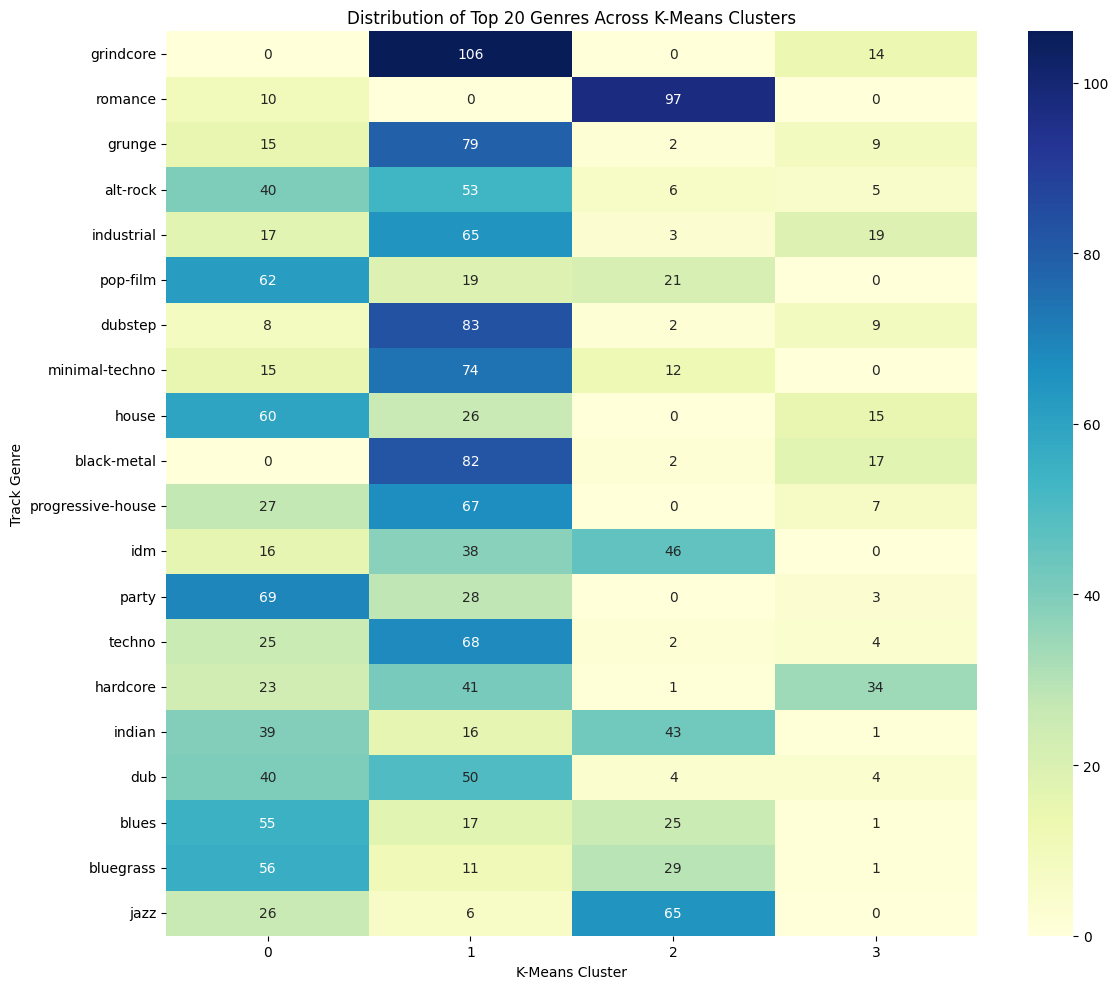

In [ ]:
# Map the sample indices back to df_clean to get the corresponding genres
sampled_genres = df_clean.iloc[sample_indices]['track_genre']

# Create a DataFrame for comparison
comparison_df = pd.DataFrame({
    'Cluster': kmeans_labels,
    'Genre': sampled_genres
})

# Create a crosstabulation
crosstab = pd.crosstab(comparison_df['Genre'], comparison_df['Cluster'])

# For visualization, let's select the top 20 most frequent genres in our sample
top_genres = comparison_df['Genre'].value_counts().head(20).index
crosstab_filtered = crosstab.loc[top_genres]

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(crosstab_filtered, annot=True, fmt='d', cmap='YlGnBu', cbar=True)
plt.title('Distribution of Top 20 Genres Across K-Means Clusters')
plt.xlabel('K-Means Cluster')
plt.ylabel('Track Genre')
plt.tight_layout()
plt.show()